<a href="https://colab.research.google.com/github/Syeda-Maham-fatima05/Intelligent-Vacuum-Cleaning-Robot/blob/main/BFS/BFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [102]:
import ast
import heapq
import itertools
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque

In [103]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded.keys()))

print("Uploaded file:", filename)

Saving Environment.txt to Environment (3).txt
Uploaded file: Environment (3).txt


In [104]:
def parse_coordinates(text):
    coordinates = ast.literal_eval(text.strip())

    # Convert a single coordinate into a list
    if (
        isinstance(coordinates, tuple)
        and len(coordinates) == 2
        and all(isinstance(x, int) for x in coordinates)
    ):
        coordinates = [coordinates]

    return [tuple(point) for point in coordinates]


def load_environment(filename):

    with open(filename, "r") as file:
        lines = [line.strip() for line in file if line.strip()]

    # Read grid dimensions
    rows, cols = map(int, lines[0].split(","))

    # Read obstacle information
    obstacle_count = int(lines[1])
    obstacles = set(parse_coordinates(lines[2]))

    # Read dirty location information
    dirty_count = int(lines[3])
    dirty_locations = parse_coordinates(lines[4])

    # Read charging station
    charging_station = parse_coordinates(lines[5])[0]

    grid = {
        "rows": rows,
        "cols": cols,
        "obstacles": obstacles,
        "dirty_locations": dirty_locations,
        "charging_station": charging_station
    }

    return grid

In [105]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


In [106]:
def validate_environment(grid):

    rows = grid["rows"]
    cols = grid["cols"]
    obstacles = grid["obstacles"]
    dirty = grid["dirty_locations"]
    charging = grid["charging_station"]

    errors = []

    # Check grid dimensions
    if rows < 8 or cols < 8:
        errors.append("Grid must be at least 8x8.")

    # Check obstacle count
    if len(obstacles) < 6:
        errors.append("At least 6 obstacles are required.")

    # Check dirty locations
    if len(dirty) < 4:
        errors.append("At least 4 dirty locations are required.")

    # Check duplicate coordinates
    if len(dirty) != len(set(dirty)):
        errors.append("Duplicate dirty locations found.")

    # Check coordinate boundaries
    all_positions = obstacles | set(dirty) | {charging}

    for r, c in all_positions:
        if not (0 <= r < rows and 0 <= c < cols):
            errors.append(f"Coordinate {(r, c)} is outside the grid.")

    # Check overlapping positions
    if obstacles.intersection(dirty):
        errors.append("An obstacle overlaps a dirty location.")

    if charging in obstacles:
        errors.append("Charging station overlaps an obstacle.")

    if charging in dirty:
        errors.append("Charging station overlaps a dirty location.")

    # Check every dirty location is reachable
    for location in dirty:
        if not is_reachable(charging, location, grid):
            errors.append(f"Dirty location {location} is unreachable.")

    if errors:
        print("Environment is INVALID:")
        for error in errors:
            print("-", error)
        return False

    print("Environment is VALID!")
    return True

In [107]:
def is_reachable(start, goal, grid):

    queue = deque([start])
    visited = {start}

    while queue:

        current = queue.popleft()

        if current == goal:
            return True

        for next_state, action, cost in get_successors(current, grid):

            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)

    return False

In [108]:
grid = load_environment(filename)

print("Grid Size:", grid["rows"], "x", grid["cols"])
print("Obstacles:", grid["obstacles"])
print("Dirty Locations:", grid["dirty_locations"])
print("Charging Station:", grid["charging_station"])

Grid Size: 8 x 8
Obstacles: {(2, 4), (6, 5), (0, 0), (6, 1), (7, 3), (0, 5), (3, 6), (3, 2)}
Dirty Locations: [(5, 3), (4, 4), (1, 2), (6, 7)]
Charging Station: (0, 7)


In [109]:
def display_grid(grid):

    rows = grid["rows"]
    cols = grid["cols"]

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)

    # Draw grid cells
    for r in range(rows):
        for c in range(cols):

            color = "white"
            label = ""

            if (r, c) in grid["obstacles"]:
                color = "gray"
                label = "X"

            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                index = grid["dirty_locations"].index((r, c))
                label = f"D{index + 1}"

            elif (r, c) == grid["charging_station"]:
                color = "lightgreen"
                label = "C"

            rect = plt.Rectangle(
                (c, r), 1, 1,
                facecolor=color,
                edgecolor="black"
            )

            ax.add_patch(rect)

            ax.text(
                c + 0.5,
                r + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold"
            )

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticklabels(range(cols))
    ax.set_yticklabels(range(rows))

    ax.set_title("Vacuum Cleaning Robot Environment")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.grid(False)
    plt.show()

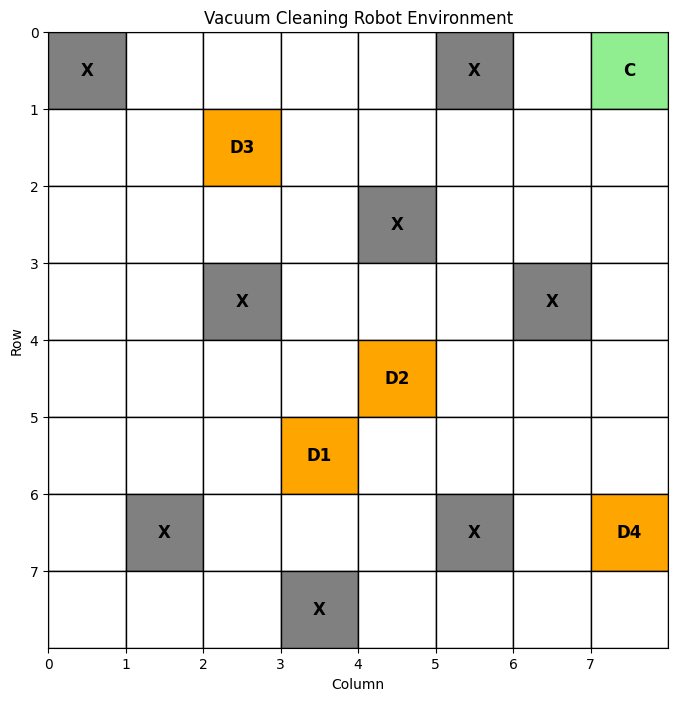

In [110]:
display_grid(grid)

In [111]:
def get_successors(state, grid):

    row, col = state

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    successors = []

    for dr, dc, action in moves:

        new_row = row + dr
        new_col = col + dc

        next_state = (new_row, new_col)

        # Check grid boundaries and obstacles
        if (
            0 <= new_row < grid["rows"]
            and 0 <= new_col < grid["cols"]
            and next_state not in grid["obstacles"]
        ):

            successors.append((next_state, action, 1))

    return successors

In [112]:
environment_valid = validate_environment(grid)

Environment is VALID!


In [113]:
def goal_test(state, goal_state):

    return state == goal_state

In [114]:
def path_cost(path):

    if not path:
        return 0

    return len(path) - 1

In [115]:
example_path = [(0, 7), (1, 7), (1, 6), (2, 6)]

print("Path Cost:", path_cost(example_path))

Path Cost: 3


In [116]:
def heuristic(state, goal_state):

    row1, col1 = state
    row2, col2 = goal_state

    return abs(row1 - row2) + abs(col1 - col2)

In [117]:
print(heuristic((0, 7), (5, 3)))

9


### 7. Breadth-First Search (BFS)

Breadth-First Search is an uninformed search algorithm. It does not use a
heuristic and has no knowledge of where the goal is. It explores the grid
level by level: first all cells one move from the start, then all cells two
moves away, and so on.

It uses a FIFO queue as the frontier. A parent dictionary records how each
cell was reached, so the final path can be rebuilt. The same dictionary also
works as the discovered set, so no cell is added to the queue twice.

The algorithm returns:
- The path from the start to the goal.
- The total path cost.
- The number of nodes expanded.

If no path exists, it returns None, an infinite cost and the number of
nodes expanded before the queue became empty.

### 7.1 Working Principle of BFS

1. Place the start position in the queue.
2. Remove the oldest position from the queue.
3. If it is the goal, rebuild the path using the parent dictionary.
4. Otherwise, count it as expanded and generate its valid successors.
5. Add each undiscovered successor to the queue and record its parent.
6. Repeat until the goal is found or the queue is empty.

Since every move costs 1, BFS reaches each cell by the fewest possible
moves. It is therefore complete and optimal in this environment.
Its drawback is that it expands many cells in all directions, including
ones that lead away from the goal.

Nodes are counted when they are expanded, after the goal test. This is
the same counting rule used in the GBFS implementation, so the results
can be compared fairly.

In [119]:
def breadth_first_search(start, goal, grid):
    """Breadth-First Search.
    Returns (path, cost, nodes_expanded).
    Returns (None, inf, nodes_expanded) if no path exists."""

    frontier = deque([start])      # FIFO queue
    parent = {start: None}         # parent links and discovered set
    nodes_expanded = 0

    while frontier:
        current = frontier.popleft()

        # Goal test
        if goal_test(current, goal):
            path = []
            state = current
            while state is not None:
                path.append(state)
                state = parent[state]
            path.reverse()
            return path, path_cost(path), nodes_expanded

        # Expand the node
        nodes_expanded += 1

        for next_state, action, step_cost in get_successors(current, grid):
            if next_state not in parent:
                parent[next_state] = current
                frontier.append(next_state)

    # No path found
    return None, float("inf"), nodes_expanded

### 7.2 Testing BFS on All Dirty Locations

The robot starts at the charging station and BFS finds a path to each
dirty location separately. For every search, the path, total cost and
number of nodes expanded are displayed.

In [120]:
start = grid["charging_station"]

if environment_valid:
    for index, goal in enumerate(grid["dirty_locations"]):
        path, cost, expanded = breadth_first_search(start, goal, grid)

        print(f"\nD{index + 1}: {goal}")
        print("Path:", path)
        print("Total Cost:", cost)
        print("Nodes Expanded:", expanded)


D1: (5, 3)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3)]
Total Cost: 9
Nodes Expanded: 39

D2: (4, 4)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (4, 6), (4, 5), (4, 4)]
Total Cost: 7
Nodes Expanded: 26

D3: (1, 2)
Path: [(0, 7), (1, 7), (1, 6), (1, 5), (1, 4), (1, 3), (1, 2)]
Total Cost: 6
Nodes Expanded: 22

D4: (6, 7)
Path: [(0, 7), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7), (6, 7)]
Total Cost: 6
Nodes Expanded: 16


### 7.3 Edge Cases

Two special cases are tested:
1. The start and goal are the same cell. BFS should return a one-cell
   path with cost 0 and no nodes expanded.
2. The goal is surrounded by obstacles. BFS should return no path and an
   infinite cost after exhausting all reachable cells.

In [121]:
# Case 1: start equals goal
print("Start equals goal:")
print(breadth_first_search(start, start, grid))

# Case 2: unreachable goal (goal enclosed by obstacles)
test_grid = {
    "rows": 8,
    "cols": 8,
    "obstacles": {(2, 3), (3, 2), (3, 4), (4, 3)},
    "dirty_locations": [(3, 3)],
    "charging_station": (0, 0),
    "declared_obstacle_count": 4,
    "declared_dirty_count": 1
}

path, cost, expanded = breadth_first_search((0, 0), (3, 3), test_grid)
print("\nUnreachable goal:")
print("Path:", path)
print("Cost:", cost)
print("Nodes Expanded:", expanded)

Start equals goal:
([(0, 7)], 0, 0)

Unreachable goal:
Path: None
Cost: inf
Nodes Expanded: 59


In [123]:
print("=" * 50)
print("FINAL BFS RESULTS")
print("=" * 50)

for index, goal in enumerate(grid["dirty_locations"]):
    path, cost, expanded = breadth_first_search(
        grid["charging_station"], goal, grid
    )
    print(f"\nDirty Location D{index + 1}: {goal}")
    if path is not None:
        print("Status: SUCCESS")
        print("Path Cost:", cost)
        print("Nodes Expanded:", expanded)
    else:
        print("Status: FAILURE")
        print("No valid path exists.")

FINAL BFS RESULTS

Dirty Location D1: (5, 3)
Status: SUCCESS
Path Cost: 9
Nodes Expanded: 39

Dirty Location D2: (4, 4)
Status: SUCCESS
Path Cost: 7
Nodes Expanded: 26

Dirty Location D3: (1, 2)
Status: SUCCESS
Path Cost: 6
Nodes Expanded: 22

Dirty Location D4: (6, 7)
Status: SUCCESS
Path Cost: 6
Nodes Expanded: 16


### 7.4 Visualization of BFS Paths and Explored Cells

This section provides reusable visualization functions:

- visualize_bfs(): draws one BFS search. The final path is shown as a blue
  line, and the cells expanded during the search are shaded light blue.
- visualize_all_bfs(): draws the BFS path from the charging station to
  every dirty location, one panel per location, with the cost and number
  of expanded nodes in each title.

The shaded region shows that BFS expands cells in every direction, not
only towards the goal. This makes its behavior easy to compare with GBFS.

In [124]:
import math

def bfs_expanded_cells(start, goal, grid):
    """Returns the list of cells BFS expands, in order.
    Uses the same logic as breadth_first_search, so its length
    equals nodes_expanded."""
    frontier = deque([start])
    discovered = {start}
    expanded = []

    while frontier:
        current = frontier.popleft()
        if goal_test(current, goal):
            break
        expanded.append(current)
        for next_state, action, step_cost in get_successors(current, grid):
            if next_state not in discovered:
                discovered.add(next_state)
                frontier.append(next_state)

    return expanded


def draw_bfs_on_axis(ax, grid, path, explored, title):
    rows, cols = grid["rows"], grid["cols"]
    ax.set_xlim(0, cols)
    ax.set_ylim(rows, 0)
    ax.set_aspect("equal")

    for r in range(rows):
        for c in range(cols):
            color, label = "white", ""
            if (r, c) in grid["obstacles"]:
                color, label = "gray", "X"
            elif (r, c) in grid["dirty_locations"]:
                color = "orange"
                label = f"D{grid['dirty_locations'].index((r, c)) + 1}"
            elif (r, c) == grid["charging_station"]:
                color, label = "lightgreen", "C"
            elif (r, c) in explored:
                color = "lightblue"

            ax.add_patch(plt.Rectangle((c, r), 1, 1,
                         facecolor=color, edgecolor="black"))
            if label:
                ax.text(c + 0.5, r + 0.5, label, ha="center",
                        va="center", fontsize=10, fontweight="bold")

    if path:
        xs = [col + 0.5 for row, col in path]
        ys = [row + 0.5 for row, col in path]
        ax.plot(xs, ys, color="blue", linewidth=2.5, marker="o",
                markersize=5)

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")


def visualize_bfs(grid, start, goal, show_explored=True):
    """Runs BFS from start to goal and draws the result."""
    path, cost, expanded = breadth_first_search(start, goal, grid)

    if path is None:
        print(f"No path from {start} to {goal}. "
              f"Nodes expanded: {expanded}")
        return

    explored = set(bfs_expanded_cells(start, goal, grid)) \
        if show_explored else set()

    fig, ax = plt.subplots(figsize=(7, 7))
    draw_bfs_on_axis(
        ax, grid, path, explored,
        f"BFS: {start} to {goal} | Cost: {cost} | Expanded: {expanded}"
    )
    plt.show()


def visualize_all_bfs(grid, show_explored=True):
    """Draws the BFS path from the charging station to every dirty
    location, one panel per location."""
    start = grid["charging_station"]
    n = len(grid["dirty_locations"])
    n_cols = 2
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(7 * n_cols, 7 * n_rows))
    axes = axes.flatten() if n > 1 else [axes]

    for i, goal in enumerate(grid["dirty_locations"]):
        path, cost, expanded = breadth_first_search(start, goal, grid)
        explored = set(bfs_expanded_cells(start, goal, grid)) \
            if (show_explored and path) else set()
        draw_bfs_on_axis(
            axes[i], grid, path, explored,
            f"D{i + 1} {goal} | Cost: {cost} | Expanded: {expanded}"
        )

    for j in range(n, len(axes)):      # hide unused panels
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

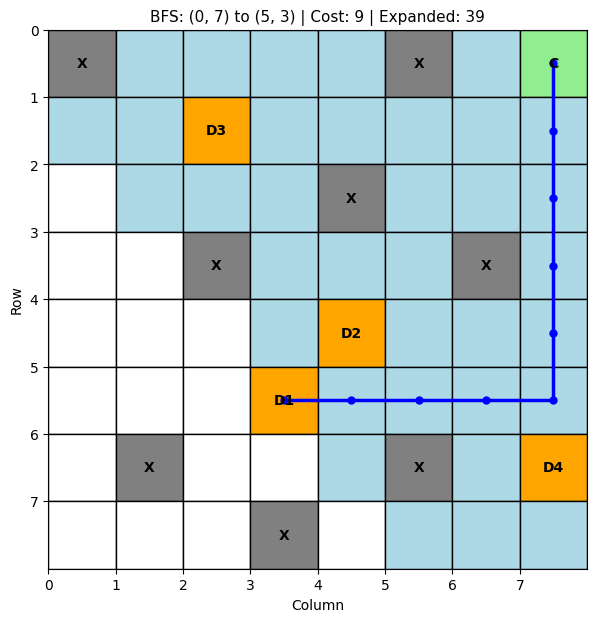

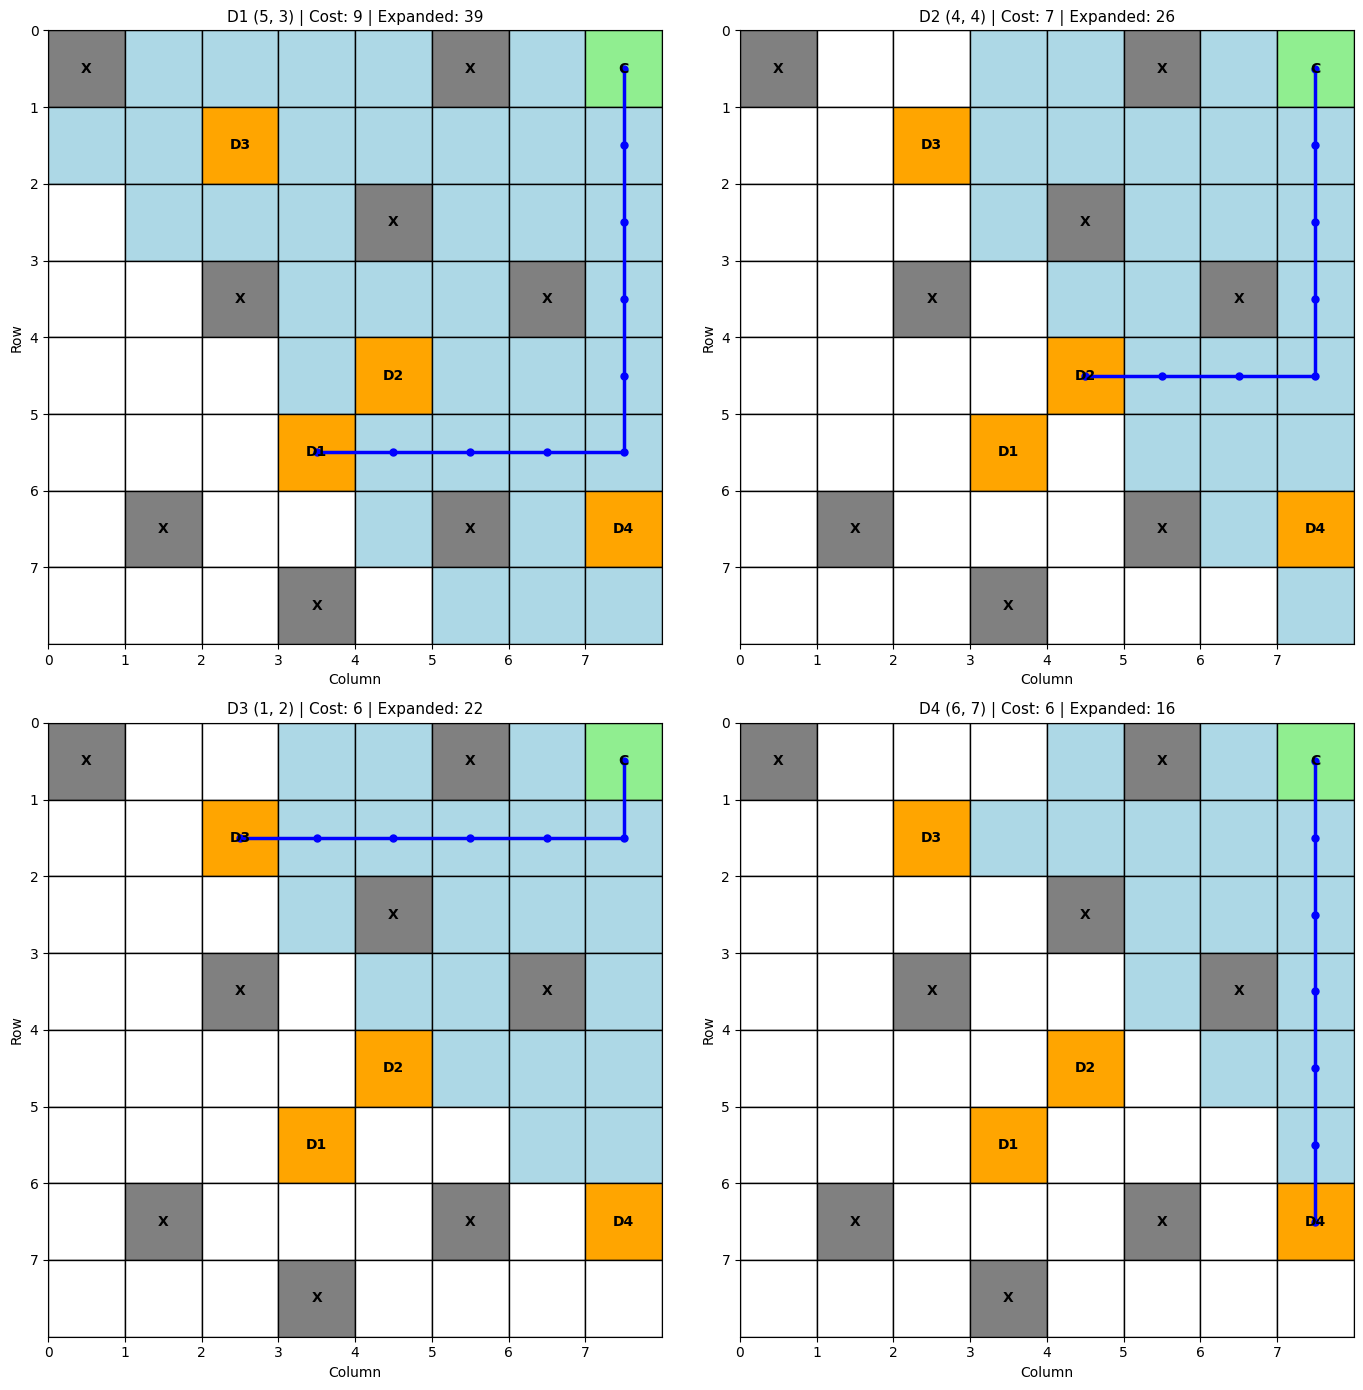

In [126]:
start = grid["charging_station"]

# One search, with explored cells shaded
visualize_bfs(grid, start, grid["dirty_locations"][0])

# All dirty locations in one figure
visualize_all_bfs(grid)

In [127]:
p, c, e = breadth_first_search(start, grid["dirty_locations"][0], grid)
print(e == len(bfs_expanded_cells(start, grid["dirty_locations"][0], grid)))

True
